In [1]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

%matplotlib inline

### 2. Load and Prepare the Data

In [2]:
# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Select two features
X = df[['sepal length (cm)', 'petal length (cm)']]

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (150, 2)


### 3. Create Dendrograms

Generate four dendrograms using:

Single linkage + Euclidean distance
Single linkage + City Block (Manhattan) distance
Complete linkage + Euclidean distance
Complete linkage + City Block (Manhattan) distance

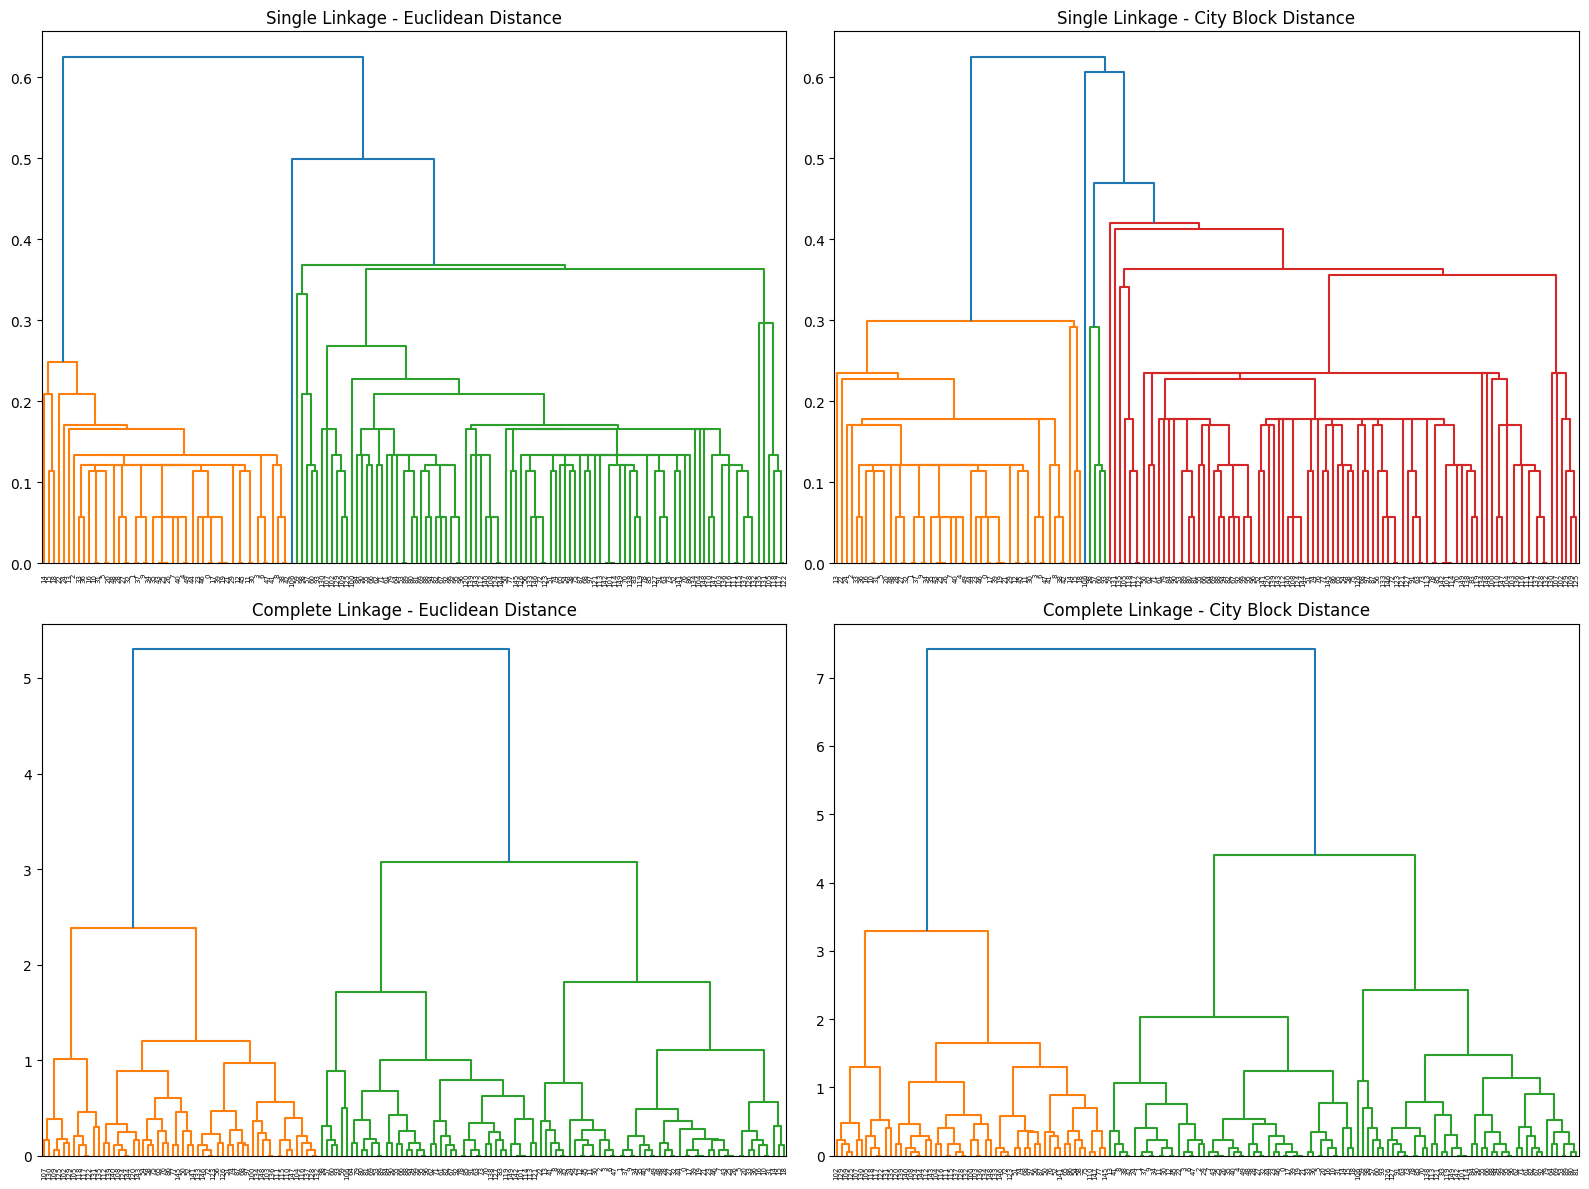

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Single linkage + Euclidean
Z1 = linkage(X_scaled, method='single', metric='euclidean')
dendrogram(Z1, ax=axes[0, 0])
axes[0, 0].set_title('Single Linkage - Euclidean Distance')

# Single linkage + City Block
Z2 = linkage(X_scaled, method='single', metric='cityblock')
dendrogram(Z2, ax=axes[0, 1])
axes[0, 1].set_title('Single Linkage - City Block Distance')

# Complete linkage + Euclidean
Z3 = linkage(X_scaled, method='complete', metric='euclidean')
dendrogram(Z3, ax=axes[1, 0])
axes[1, 0].set_title('Complete Linkage - Euclidean Distance')

# Complete linkage + City Block
Z4 = linkage(X_scaled, method='complete', metric='cityblock')
dendrogram(Z4, ax=axes[1, 1])
axes[1, 1].set_title('Complete Linkage - City Block Distance')

plt.tight_layout()
plt.show()

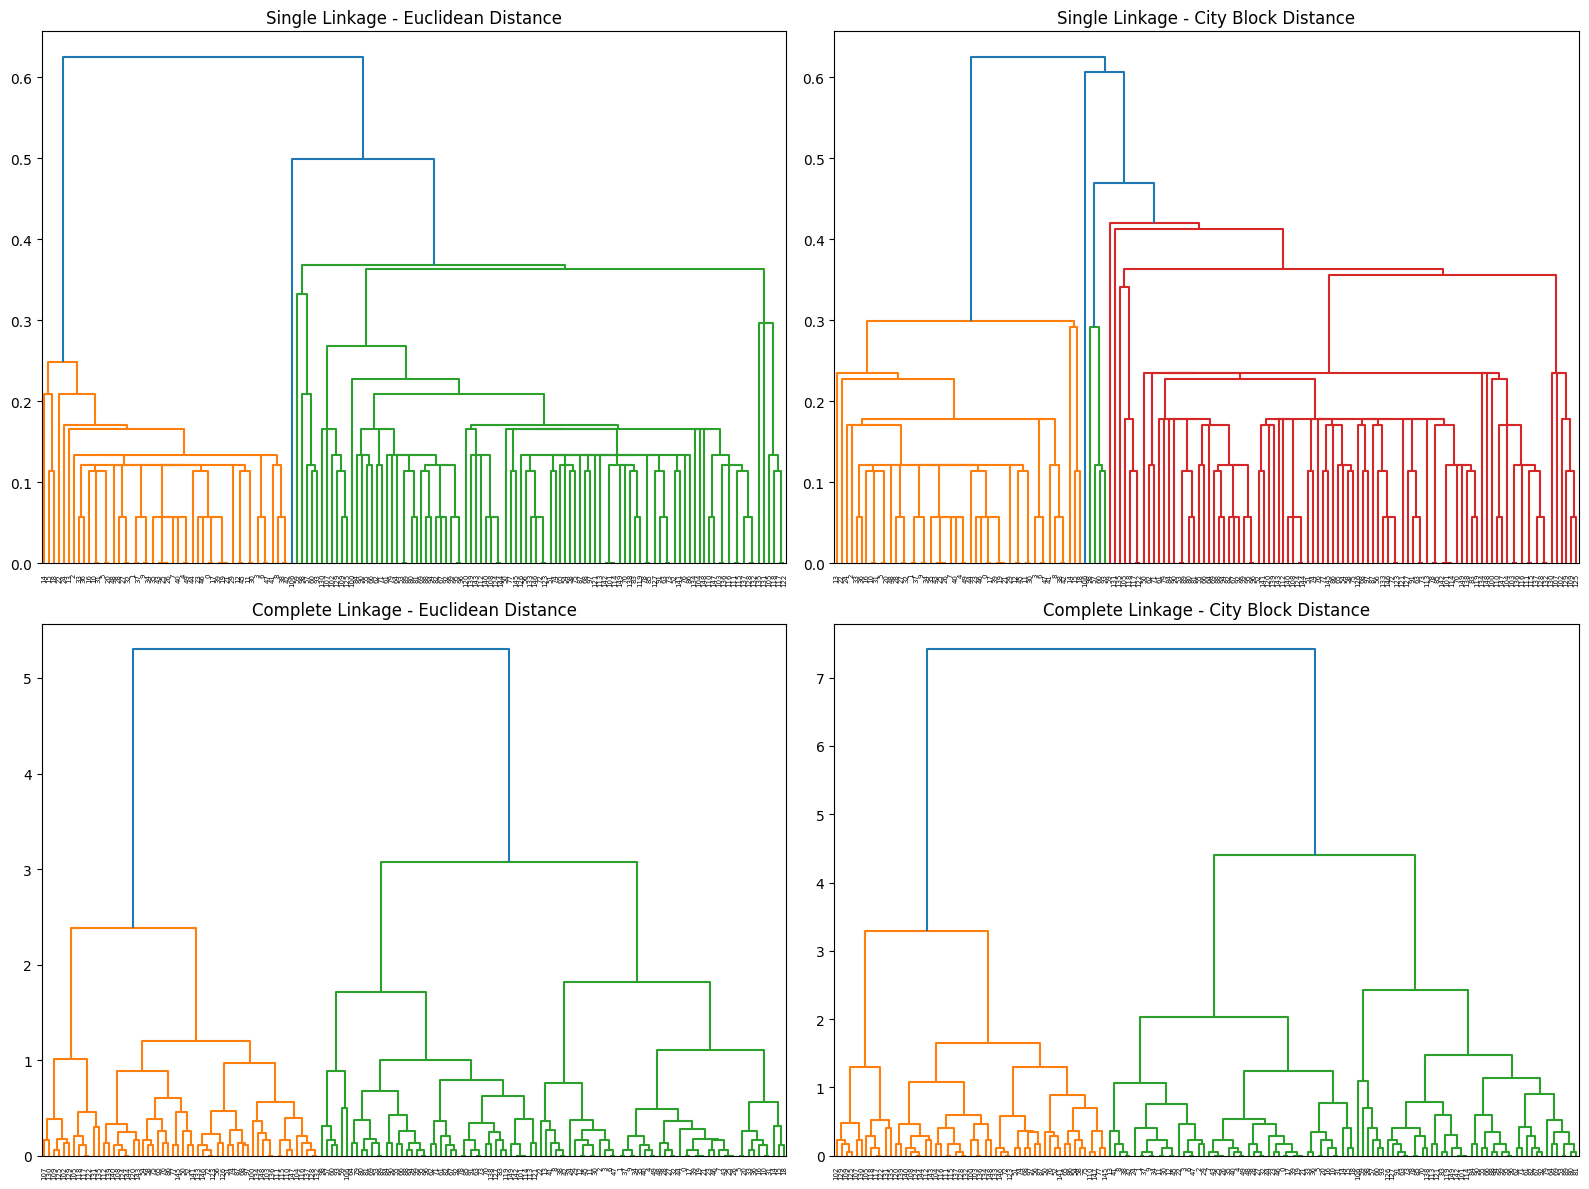

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Single linkage + Euclidean
Z1 = linkage(X_scaled, method='single', metric='euclidean')
dendrogram(Z1, ax=axes[0, 0])
axes[0, 0].set_title('Single Linkage - Euclidean Distance')

# Single linkage + City Block
Z2 = linkage(X_scaled, method='single', metric='cityblock')
dendrogram(Z2, ax=axes[0, 1])
axes[0, 1].set_title('Single Linkage - City Block Distance')

# Complete linkage + Euclidean
Z3 = linkage(X_scaled, method='complete', metric='euclidean')
dendrogram(Z3, ax=axes[1, 0])
axes[1, 0].set_title('Complete Linkage - Euclidean Distance')

# Complete linkage + City Block
Z4 = linkage(X_scaled, method='complete', metric='cityblock')
dendrogram(Z4, ax=axes[1, 1])
axes[1, 1].set_title('Complete Linkage - City Block Distance')

plt.tight_layout()
plt.show()

### 4. Choose a Dendrogram
Selected Dendrogram:

Complete Linkage with Euclidean Distance

Reason:

Produces more compact and clearly separated clusters.
Avoids the chaining effect often seen in single linkage.
Shows clearer cluster divisions in the Iris data.

From the dendrogram, we choose 3 clusters because there appears to be a large jump in linkage distance before the final merges.

In [5]:
# Hierarchical clustering
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='complete',
    metric='euclidean'
)

clusters = hc.fit_predict(X_scaled)

# Add cluster labels to dataframe
df['Cluster'] = clusters

print(df[['sepal length (cm)', 'petal length (cm)', 'Cluster']].head())

   sepal length (cm)  petal length (cm)  Cluster
0                5.1                1.4        1
1                4.9                1.4        1
2                4.7                1.3        1
3                4.6                1.5        1
4                5.0                1.4        1


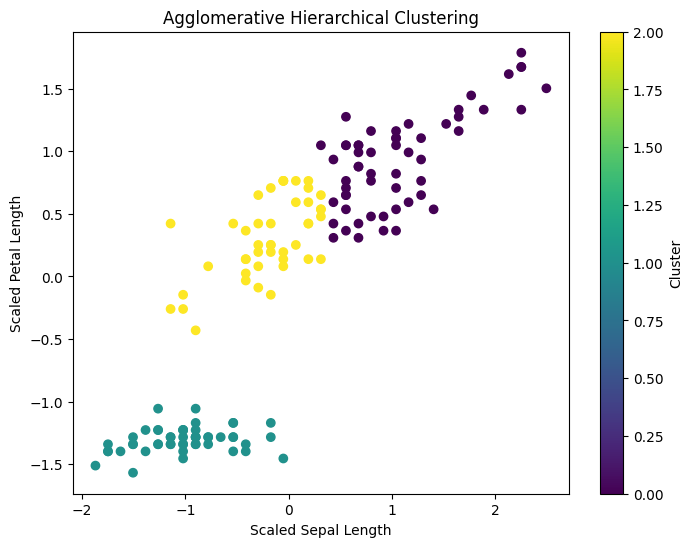

In [6]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=clusters,
    cmap='viridis'
)

plt.xlabel('Scaled Sepal Length')
plt.ylabel('Scaled Petal Length')
plt.title('Agglomerative Hierarchical Clustering')
plt.colorbar(label='Cluster')
plt.show()

In [7]:
score = silhouette_score(X_scaled, clusters)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.534


In [8]:
print(f"Silhouette Score = {score:.3f}")

Silhouette Score = 0.534
